In [1]:
# Import core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import Machine Learning modules
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer

# Set plotting style
sns.set_theme(style="whitegrid", palette="muted")
import warnings
warnings.filterwarnings('ignore')

# Loading the dataset
df = pd.read_csv('./data/raw/Dataset.csv')
print(f"Dataset loaded with {df.shape[0]} rows and {df.shape[1]} columns.")
df.head(3)

Dataset loaded with 8790 rows and 10 columns.


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"


In [2]:
# 1. Handle Missing Values
df.fillna({'director': 'Unknown', 'country': 'Unknown', 'rating': 'NR', 'duration': '0 min'}, inplace=True)

# 2. Extract numerical duration (minutes for movies, seasons for TV shows)
# We will create a unified 'duration_value' column
df['duration_value'] = df['duration'].str.extract('(\d+)').astype(float)

# Fill any remaining NaNs in duration with the median
df['duration_value'].fillna(df['duration_value'].median(), inplace=True)

# 3. Process the 'listed_in' column (Genres)
# Since titles can have multiple genres separated by commas, we create dummy variables for each genre
genres_dummies = df['listed_in'].str.get_dummies(sep=', ')

print("Features extracted successfully.")
genres_dummies.head(3)

Features extracted successfully.


,Action & Adventure,Anime Features,Anime Series,British TV Shows,Children & Family Movies,Classic & Cult TV,Classic Movies,Comedies,Crime TV Shows,Cult Movies,...,TV Action & Adventure,TV Comedies,TV Dramas,TV Horror,TV Mysteries,TV Sci-Fi & Fantasy,TV Shows,TV Thrillers,Teen TV Shows,Thrillers
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,1,1,0,0,0,0,0


In [3]:
# 1. One-Hot Encode 'type' (Movie vs TV Show) and 'rating'
categorical_features = pd.get_dummies(df[['type', 'rating']], drop_first=False)

# 2. Select numerical features
numerical_features = df[['release_year', 'duration_value']]

# 3. Combine everything into a single feature matrix
X = pd.concat([numerical_features, categorical_features, genres_dummies], axis=1)

# 4. Standardize the data (Crucial for K-Means based on Euclidean distance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Final Feature Matrix Shape: {X_scaled.shape}")

Final Feature Matrix Shape: (8790, 60)


Reduced dimensions from 60 to 48 using PCA.


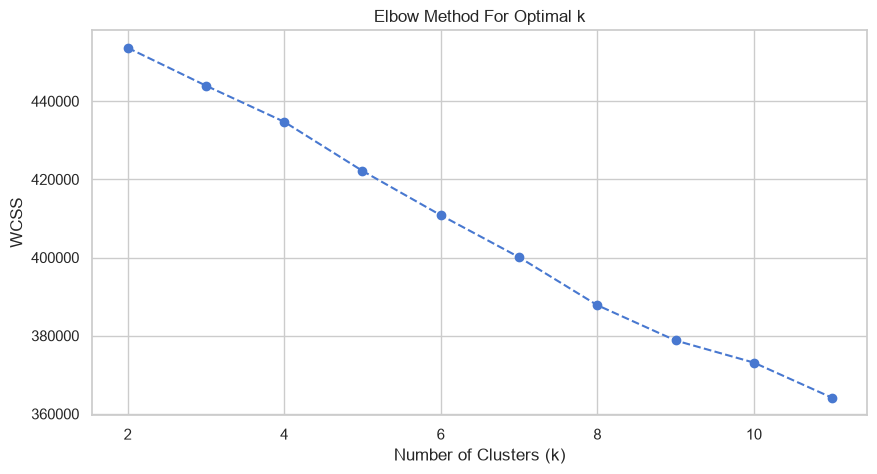

In [4]:
# Reduce dimensions to capture 95% of the variance
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"Reduced dimensions from {X_scaled.shape[1]} to {X_pca.shape[1]} using PCA.")

# Calculate Within-Cluster-Sum-of-Squares (WCSS) for the Elbow Method
wcss = []
k_range = range(2, 12)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, random_state=42)
    kmeans.fit(X_pca)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(k_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.show()

In [5]:
optimal_k = 5 # Change this based on the elbow plot from Cell 4

# Fit final K-Means model
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', max_iter=300, random_state=42)
cluster_labels = kmeans.fit_predict(X_pca)

# Add cluster labels back to the original dataframe
df['Cluster'] = cluster_labels
print("Clustering complete. Groups assigned to dataset.")

Clustering complete. Groups assigned to dataset.


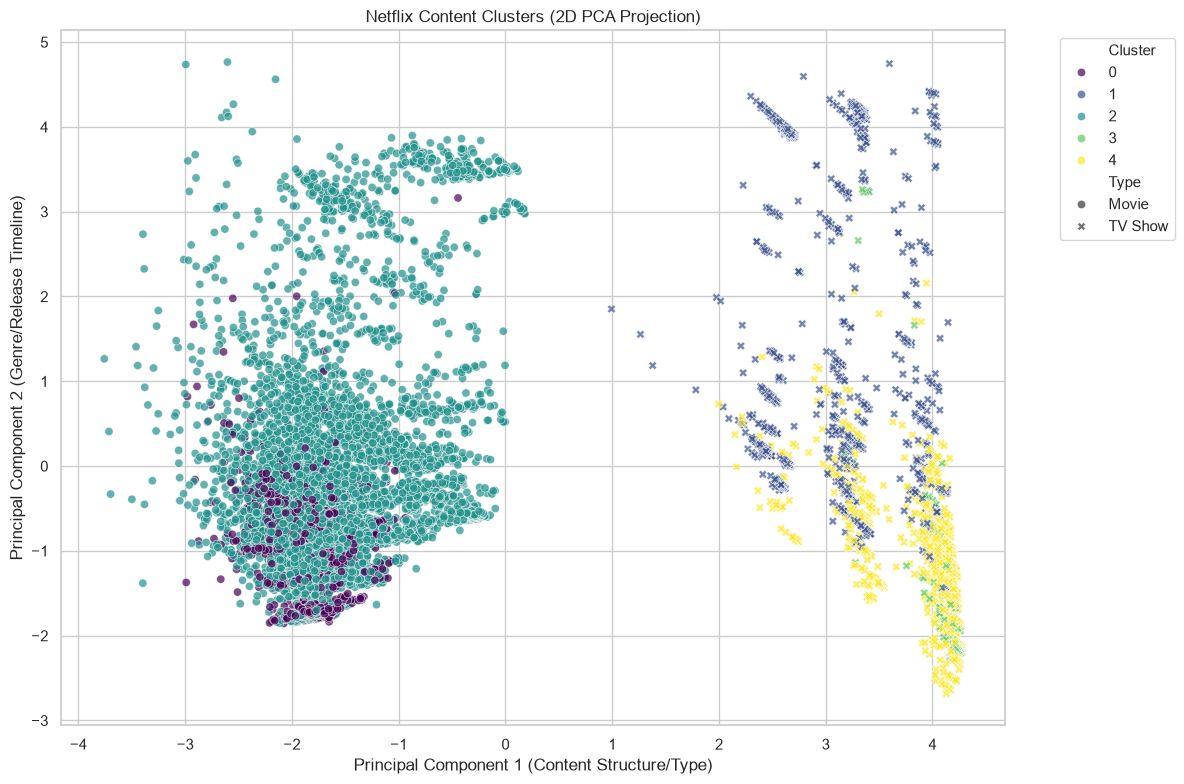

In [6]:
# Create a DataFrame for visualization using the first two PCA components
pca_df = pd.DataFrame(data=X_pca[:, :2], columns=['PCA_1', 'PCA_2'])
pca_df['Cluster'] = df['Cluster']
pca_df['Type'] = df['type']

plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='PCA_1', 
    y='PCA_2', 
    hue='Cluster', 
    style='Type',
    data=pca_df, 
    palette='viridis', 
    alpha=0.7
)

plt.title('Netflix Content Clusters (2D PCA Projection)')
plt.xlabel('Principal Component 1 (Content Structure/Type)')
plt.ylabel('Principal Component 2 (Genre/Release Timeline)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [7]:
# Analyze the numerical characteristics of each cluster
cluster_summary = df.groupby('Cluster').agg({
    'release_year': ['mean', 'min', 'max'],
    'duration_value': 'mean',
    'type': lambda x: x.mode()[0], # Most common type
    'rating': lambda x: x.mode()[0] # Most common rating
}).round(1)

print("--- Cluster Profiles ---")
display(cluster_summary)

# Analyze top genres per cluster
for c in range(optimal_k):
    cluster_data = df[df['Cluster'] == c]
    
    # Flatten the comma-separated genres and count them
    all_genres = cluster_data['listed_in'].str.split(', ').explode()
    top_genres = all_genres.value_counts().head(3).index.tolist()
    
    print(f"Cluster {c} Dominant Genres: {', '.join(top_genres)}")

--- Cluster Profiles ---


release_year             duration_value     type   rating
                mean   min   max           mean <lambda> <lambda>
Cluster                                                          
0             2014.4  1955  2021          101.1    Movie    TV-MA
1             2016.4  1925  2021            1.8  TV Show    TV-MA
2             2012.9  1942  2021           99.4    Movie    TV-MA
3             2017.5  1979  2021            1.5  TV Show    TV-MA
4             2016.7  1963  2021            1.8  TV Show    TV-MA

Cluster 0 Dominant Genres: Independent Movies, Dramas, International Movies
Cluster 1 Dominant Genres: Kids' TV, Docuseries, TV Comedies
Cluster 2 Dominant Genres: International Movies, Dramas, Comedies
Cluster 3 Dominant Genres: Spanish-Language TV Shows, International TV Shows, Crime TV Shows
Cluster 4 Dominant Genres: International TV Shows, TV Dramas, Romantic TV Shows
